# RIN - experiment 7b: controlled-source transfer on a seeded embryonic subgraph

This notebook is the controlled-source follow-up to experiment 7a.

7a showed that, on a real seeded embryonic subgraph, automatic query anchoring
was noisy enough to dominate the whole retrieval pipeline. As a result, 7a did
not cleanly separate the post-diffusion correction families.

7b fixes that *experimentally*, not architecturally:

- source anchors are set manually per query;
- source nodes are excluded from the reported retrieval ranking;
- the same retrieval families are then re-tested on two graph variants:
  ConceptNet-only and ConceptNet+ATOMIC.

So 7b is not a repaired 7a. It is a new controlled-source test of the memory
dynamics proper.


In [1]:
import sys
from pathlib import Path


def find_repo_root(marker="requirements.txt"):
    path = Path.cwd()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"could not find repo root (looked for {marker})")


REPO_ROOT = find_repo_root()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Repo root:", REPO_ROOT)


Repo root: c:\Users\yaros\BlackSabbitch_repo\RIN


In [2]:
from __future__ import annotations

from collections import Counter
import re

import numpy as np

from embryonic import conceptnet_source
from embryonic.loader import EmbryonicGraphLoader
from embryonic.numberbatch import Numberbatch
from memory.diffuse import diffuse
from memory.graph import MemoryGraph
from memory.pagerank import (
    in_strength_prior,
    weighted_in_strengths,
    weighted_out_strengths,
    weighted_pagerank,
)

try:
    import matplotlib.pyplot as plt
except Exception:
    plt = None

try:
    import pandas as pd
except Exception:
    pd = None


In [3]:
SOURCE_DIR = REPO_ROOT / "source"

CONCEPTNET_DUMP = SOURCE_DIR / "conceptnet-assertions-5.7.0.csv.gz"
ATOMIC_CSV = SOURCE_DIR / "v4_atomic_all_agg.csv"
NUMBERBATCH_FILE = SOURCE_DIR / "numberbatch-en-19.08.txt.gz"

LANGUAGE = "en"
CONCEPTNET_BACKEND = "local_dump"
ATOMIC_FUZZY_LINKING = False
MIN_RELATED_TO_WEIGHT = 2.0

SEED_ENTRIES = [
    "coffee",
    "caffeine",
    "beverage",
    "energy",
    "water",
    "passport",
    "boarding pass",
    "check in",
    "airport",
    "travel",
    "hotel",
    "laptop",
    "charger",
    "office",
    "apartment",
    "wallet",
    "keys",
    "cats",
    "umbrella",
    "outdoor gear",
    "breakfast",
    "wake up",
    "espresso",
]

BASE_RADIUS = 3
LIMIT_PER_NODE = 30
MAX_NODES = 10_000

SOURCE_AMPLITUDE = 100.0
EXCLUDE_SOURCE_NODES = True
RUN_OPTIONAL_M5 = False

DIFFUSE_KW = {
    "decay": 0.8,
    "min_propagate_fraction": 0.01,
    "max_steps": 20,
}

TERM_VARIANTS = {
    "home": ["home", "house", "home life"],
    "work": ["work", "office", "working"],
    "trip": ["trip", "travel", "travel planning"],
    "travel": ["travel", "travel planning", "trip"],
    "boarding pass": ["boarding pass", "boarding_pass"],
    "check in": ["check in", "check_in", "checking in"],
    "power": ["power", "electricity"],
    "apartment building": ["apartment building", "apartment complex", "block of flats"],
    "living": ["living", "live", "good life"],
    "pack suitcase": ["pack suitcase", "suitcase"],
}

GRAPH_VARIANTS = [
    {
        "name": "concept_only",
        "label": "ConceptNet only",
        "include_atomic": False,
    },
    {
        "name": "concept_plus_atomic",
        "label": "ConceptNet + ATOMIC",
        "include_atomic": True,
    },
]

QUERY_SPECS = [
    {
        "id": "Q1",
        "query": "why coffee gives energy",
        "anchors": ["coffee", "energy"],
        "anchor_fallbacks": [],
        "correct": ["caffeine"],
        "distractors": ["beverage", "water"],
        "pairwise": [("caffeine", "beverage")],
    },
    {
        "id": "Q2",
        "query": "what matters at check in",
        "anchors": ["check in", "airport"],
        "anchor_fallbacks": ["checking in"],
        "correct": ["passport", "boarding pass"],
        "distractors": ["travel", "hotel"],
        "pairwise": [("passport", "travel"), ("boarding pass", "hotel")],
    },
    {
        "id": "Q3",
        "query": "what helps after dead laptop",
        "anchors": ["laptop", "power"],
        "anchor_fallbacks": ["electricity"],
        "correct": ["charger"],
        "distractors": ["office", "work"],
        "pairwise": [("charger", "office")],
    },
    {
        "id": "Q4",
        "query": "what did i forget at home",
        "anchors": ["home", "forget"],
        "anchor_fallbacks": ["remember"],
        "correct": ["wallet", "keys"],
        "distractors": ["apartment", "cats"],
        "pairwise": [("wallet", "apartment"), ("keys", "cats")],
    },
    {
        "id": "Q5",
        "query": "tell me about apartment life",
        "anchors": ["apartment building", "living"],
        "anchor_fallbacks": ["block of flats", "live"],
        "correct": ["apartment", "home"],
        "distractors": ["wallet", "keys"],
        "pairwise": [("apartment", "wallet"), ("home", "keys")],
    },
    {
        "id": "Q6",
        "query": "tell me about travel planning",
        "anchors": ["airport", "hotel", "pack suitcase"],
        "anchor_fallbacks": ["travel planning"],
        "correct": ["travel", "trip"],
        "distractors": ["passport"],
        "pairwise": [("travel", "passport"), ("trip", "passport")],
    },
    {
        "id": "Q7",
        "query": "what to drink in the morning",
        "anchors": ["morning", "breakfast"],
        "anchor_fallbacks": ["wake up"],
        "correct": ["espresso", "coffee"],
        "distractors": ["water", "beverage"],
        "pairwise": [("espresso", "water"), ("coffee", "beverage")],
    },
]

METHODS = [
    {"name": "M0_raw", "label": "M0 raw diffusion", "kind": "raw"},
    {"name": "M1_in_strength_05", "label": "M1 raw + in-strength^0.5", "kind": "in_strength", "eta": 0.5},
    {"name": "M2_pagerank_025", "label": "M2 raw + PageRank^0.25", "kind": "pagerank", "eta": 0.25},
    {"name": "M2_pagerank_05", "label": "M2 raw + PageRank^0.5", "kind": "pagerank", "eta": 0.5},
    {"name": "M3_local_leak", "label": "M3 local leak only", "kind": "local_leak", "alpha": 1.0, "beta": 0.05, "gamma": 0.5},
    {"name": "M4_hybrid_pagerank", "label": "M4 local leak + PageRank^0.25", "kind": "hybrid_pagerank", "alpha": 1.0, "beta": 0.05, "gamma": 0.5, "eta": 0.25},
]

if RUN_OPTIONAL_M5:
    METHODS.append(
        {"name": "M5_hybrid_in_strength", "label": "M5 local leak + in-strength^0.5", "kind": "hybrid_in_strength", "alpha": 1.0, "beta": 0.05, "gamma": 0.5, "eta": 0.5}
    )


In [4]:
required_paths = [CONCEPTNET_DUMP, NUMBERBATCH_FILE]
required_paths.append(ATOMIC_CSV)
missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError("Missing required local source files:\n" + "\n".join(str(path) for path in missing))

print("All required source files are present.")
print(f"ConceptNet dump: {CONCEPTNET_DUMP}")
print(f"ATOMIC CSV:      {ATOMIC_CSV}")
print(f"Numberbatch:     {NUMBERBATCH_FILE}")

print("\nBuilding ConceptNet adjacency index once for reuse...")
adjacency = conceptnet_source.build_language_adjacency(str(CONCEPTNET_DUMP), LANGUAGE)
print(f"Indexed {len(adjacency):,} ConceptNet adjacency lists.")

print("\nLoading Numberbatch...")
numberbatch = Numberbatch()
numberbatch.load(str(NUMBERBATCH_FILE))
print(f"Loaded {len(numberbatch.terms):,} Numberbatch entries.")


All required source files are present.
ConceptNet dump: c:\Users\yaros\BlackSabbitch_repo\RIN\source\conceptnet-assertions-5.7.0.csv.gz
ATOMIC CSV:      c:\Users\yaros\BlackSabbitch_repo\RIN\source\v4_atomic_all_agg.csv
Numberbatch:     c:\Users\yaros\BlackSabbitch_repo\RIN\source\numberbatch-en-19.08.txt.gz

Building ConceptNet adjacency index once for reuse...
Indexed 1,787,373 ConceptNet adjacency lists.

Loading Numberbatch...
Loaded 516,782 Numberbatch entries.


In [5]:
def normalize_text(text: str) -> str:
    text = text.lower().replace("_", " ").strip()
    text = re.sub(r"\s+\([anvr]\)$", "", text)
    text = re.sub(r"\s+", " ", text)
    return text


def concept_term_from_provenance(uri: str) -> str | None:
    parts = uri.split("/")
    if len(parts) > 3 and parts[1] == "c":
        return parts[3].replace("_", " ")
    return None


def node_sort_key(G: MemoryGraph, node_id: int) -> tuple:
    node = G.nodes[node_id]
    content = normalize_text(node.content)
    is_concept = 0 if node.node_kind == "concept" else 1
    has_pos_suffix = 1 if "(" in node.content else 0
    return (is_concept, has_pos_suffix, len(content), node_id)


def build_label_index(G: MemoryGraph) -> dict[str, list[int]]:
    label_index: dict[str, list[int]] = {}
    for node_id, node in G.nodes.items():
        labels = {normalize_text(node.content)}
        for item in getattr(node, "provenance", []):
            if isinstance(item, str):
                term = concept_term_from_provenance(item)
                if term is not None:
                    labels.add(normalize_text(term))
        for label in labels:
            if label:
                label_index.setdefault(label, []).append(node_id)
    return label_index


def choose_best_node(G: MemoryGraph, node_ids: list[int]) -> int | None:
    if not node_ids:
        return None
    return sorted(set(node_ids), key=lambda node_id: node_sort_key(G, node_id))[0]


def resolve_term(G: MemoryGraph, label_index: dict[str, list[int]], term: str) -> tuple[int | None, str | None]:
    variants = TERM_VARIANTS.get(term, [term])
    variants = [term, *[variant for variant in variants if variant != term]]
    for variant in variants:
        node_ids = label_index.get(normalize_text(variant), [])
        chosen = choose_best_node(G, node_ids)
        if chosen is not None:
            return chosen, variant
    return None, None


def node_label(G: MemoryGraph, node_id: int) -> str:
    node = G.nodes[node_id]
    return f"{node.content} [{node.node_kind}]"


def print_table(rows: list[dict], columns: list[str]) -> None:
    if not rows:
        print("(no rows)")
        return
    widths = {column: max(len(column), *(len(str(row.get(column, ""))) for row in rows)) for column in columns}
    header = " | ".join(column.ljust(widths[column]) for column in columns)
    rule = "-+-".join("-" * widths[column] for column in columns)
    print(header)
    print(rule)
    for row in rows:
        print(" | ".join(str(row.get(column, "")).ljust(widths[column]) for column in columns))


def resolve_manual_anchors(G: MemoryGraph, label_index: dict[str, list[int]], spec: dict) -> dict:
    resolved = []
    missing = []
    tried = []

    for term in spec["anchors"]:
        node_id, resolved_as = resolve_term(G, label_index, term)
        tried.append((term, resolved_as))
        if node_id is None:
            missing.append(term)
        else:
            resolved.append({"term": term, "resolved_as": resolved_as, "node_id": node_id})

    if missing:
        for fallback in spec.get("anchor_fallbacks", []):
            node_id, resolved_as = resolve_term(G, label_index, fallback)
            tried.append((fallback, resolved_as))
            if node_id is not None:
                resolved.append({"term": fallback, "resolved_as": resolved_as, "node_id": node_id})

    seen = set()
    deduped = []
    for item in resolved:
        if item["node_id"] not in seen:
            deduped.append(item)
            seen.add(item["node_id"])

    return {
        "anchor_ids": [item["node_id"] for item in deduped],
        "anchor_labels": [node_label(G, item["node_id"]) for item in deduped],
        "resolved": deduped,
        "missing": missing,
        "trace": tried,
    }


def remove_source_nodes(scores: dict[int, float], source_ids: list[int]) -> dict[int, float]:
    if not EXCLUDE_SOURCE_NODES:
        return dict(scores)
    excluded = set(source_ids)
    return {node_id: score for node_id, score in scores.items() if node_id not in excluded}


def top_k_concepts(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[tuple[int, float]]:
    rows = [(node_id, score) for node_id, score in scores.items() if G.nodes[node_id].node_kind == "concept"]
    return sorted(rows, key=lambda item: item[1], reverse=True)[:k]


def format_top_k(G: MemoryGraph, scores: dict[int, float], k: int = 10) -> list[str]:
    return [f"{node_label(G, node_id)} :: {score:.4f}" for node_id, score in top_k_concepts(G, scores, k=k)]


def best_score(scores: dict[int, float], node_ids: list[int]) -> tuple[int | None, float | None]:
    present = [(node_id, scores.get(node_id, 0.0)) for node_id in node_ids]
    if not present:
        return None, None
    return max(present, key=lambda item: item[1])


def method_denominator(node_id: int, method: dict, out_strengths: dict[int, float], priors: dict[str, dict[int, float]]) -> float:
    kind = method["kind"]
    denominator = 1.0
    if kind in {"local_leak", "hybrid_pagerank", "hybrid_in_strength"}:
        denominator *= method["alpha"] + method["beta"] * (out_strengths[node_id] ** method["gamma"])
    if kind in {"in_strength", "hybrid_in_strength"}:
        denominator *= priors["in_strength"][node_id] ** method["eta"]
    if kind in {"pagerank", "hybrid_pagerank"}:
        denominator *= priors["pagerank"][node_id] ** method["eta"]
    return denominator


def apply_method(base_scores: dict[int, float], method: dict, out_strengths: dict[int, float], priors: dict[str, dict[int, float]]) -> dict[int, float]:
    if method["kind"] == "raw":
        return dict(base_scores)
    adjusted = {}
    for node_id, score in base_scores.items():
        denominator = method_denominator(node_id, method, out_strengths, priors)
        adjusted[node_id] = score / denominator if denominator > 0 else score
    return adjusted


In [6]:
def resolve_eval_terms(G: MemoryGraph, label_index: dict[str, list[int]], terms: list[str]) -> tuple[list[dict], list[str]]:
    resolved = []
    missing = []
    for term in terms:
        node_id, resolved_as = resolve_term(G, label_index, term)
        if node_id is None:
            missing.append(term)
        else:
            resolved.append({"term": term, "resolved_as": resolved_as, "node_id": node_id})
    return resolved, missing


def evaluate_query(G: MemoryGraph, label_index: dict[str, list[int]], spec: dict, scores_all: dict[int, float], scores_ex_source: dict[int, float], anchor_info: dict) -> dict:
    resolved_correct, missing_correct = resolve_eval_terms(G, label_index, spec["correct"])
    resolved_distractors, missing_distractors = resolve_eval_terms(G, label_index, spec["distractors"])

    correct_ids = [item["node_id"] for item in resolved_correct]
    distractor_ids = [item["node_id"] for item in resolved_distractors]

    best_correct_id, best_correct_score = best_score(scores_ex_source, correct_ids)
    best_distractor_id, best_distractor_score = best_score(scores_ex_source, distractor_ids)

    solved = None
    margin = None
    if best_correct_score is not None and best_distractor_score is not None:
        solved = best_correct_score > best_distractor_score
        margin = best_correct_score - best_distractor_score

    source_set = set(anchor_info["anchor_ids"])
    pairwise_rows = []
    skipped_pairwise = 0

    for left_term, right_term in spec["pairwise"]:
        left_id, left_resolved = resolve_term(G, label_index, left_term)
        right_id, right_resolved = resolve_term(G, label_index, right_term)
        skipped = False
        passed = None
        if left_id is None or right_id is None:
            passed = None
        elif left_id in source_set or right_id in source_set:
            skipped = True
            skipped_pairwise += 1
        else:
            passed = scores_ex_source.get(left_id, 0.0) > scores_ex_source.get(right_id, 0.0)
        pairwise_rows.append({
            "left_term": left_term,
            "left_resolved": left_resolved,
            "right_term": right_term,
            "right_resolved": right_resolved,
            "passed": passed,
            "skipped": skipped,
        })

    return {
        "id": spec["id"],
        "query": spec["query"],
        "anchor_labels": anchor_info["anchor_labels"],
        "anchor_ids": anchor_info["anchor_ids"],
        "anchor_missing": anchor_info["missing"],
        "anchor_trace": anchor_info["trace"],
        "resolved_correct": resolved_correct,
        "resolved_distractors": resolved_distractors,
        "missing_correct": missing_correct,
        "missing_distractors": missing_distractors,
        "best_correct_id": best_correct_id,
        "best_correct_score": best_correct_score,
        "best_distractor_id": best_distractor_id,
        "best_distractor_score": best_distractor_score,
        "solved": solved,
        "margin": margin,
        "pairwise": pairwise_rows,
        "skipped_pairwise": skipped_pairwise,
        "top10_all": format_top_k(G, scores_all, k=10),
        "top10_ex_source": format_top_k(G, scores_ex_source, k=10),
        "top20_ex_source": format_top_k(G, scores_ex_source, k=20),
    }


def summarize_method(results: list[dict]) -> dict:
    solved_known = [row["solved"] for row in results if row["solved"] is not None]
    margins = [row["margin"] for row in results if row["margin"] is not None]
    pairwise_values = [pair["passed"] for row in results for pair in row["pairwise"] if pair["passed"] is not None]
    skipped_pairwise = sum(row["skipped_pairwise"] for row in results)
    return {
        "queries_with_decision": len(solved_known),
        "solved_queries": sum(1 for value in solved_known if value),
        "pairwise_total": len(pairwise_values),
        "pairwise_passed": sum(1 for value in pairwise_values if value),
        "skipped_pairwise": skipped_pairwise,
        "total_margin": sum(margins),
    }


In [7]:
def loader_for_variant(variant: dict) -> EmbryonicGraphLoader:
    return EmbryonicGraphLoader(
        entries=SEED_ENTRIES,
        radius=BASE_RADIUS,
        language=LANGUAGE,
        conceptnet_backend=CONCEPTNET_BACKEND,
        conceptnet_adjacency=adjacency,
        limit_per_node=LIMIT_PER_NODE,
        max_nodes=MAX_NODES,
        min_related_to_weight=MIN_RELATED_TO_WEIGHT,
        include_atomic=variant["include_atomic"],
        atomic_path=str(ATOMIC_CSV) if variant["include_atomic"] else None,
        numberbatch=numberbatch,
        atomic_fuzzy_linking=ATOMIC_FUZZY_LINKING,
    )


def graph_stats(G: MemoryGraph, priors: dict[str, dict[int, float]], strengths: dict[str, dict[int, float]]) -> dict:
    node_kind_counts = Counter(node.node_kind for node in G.nodes.values())
    edge_count = sum(len(G.out_edges(node_id)) for node_id in G.node_ids())

    top_pagerank = [
        (node_label(G, node_id), priors["pagerank"][node_id])
        for node_id in sorted(priors["pagerank"], key=priors["pagerank"].get, reverse=True)
        if G.nodes[node_id].node_kind == "concept"
    ][:10]
    top_in_strength = [
        (node_label(G, node_id), strengths["in"][node_id])
        for node_id in sorted(strengths["in"], key=strengths["in"].get, reverse=True)
        if G.nodes[node_id].node_kind == "concept"
    ][:10]

    return {
        "nodes": len(G.nodes),
        "edges": edge_count,
        "concept_nodes": node_kind_counts.get("concept", 0),
        "episode_nodes": node_kind_counts.get("episode", 0),
        "other_kinds": {kind: count for kind, count in node_kind_counts.items() if kind not in {"concept", "episode"}},
        "top_pagerank": top_pagerank,
        "top_in_strength": top_in_strength,
    }


def run_variant(variant: dict) -> dict:
    G = loader_for_variant(variant).load()
    label_index = build_label_index(G)
    priors = {
        "pagerank": weighted_pagerank(G, damping=0.85),
        "in_strength": in_strength_prior(G),
    }
    strengths = {
        "in": weighted_in_strengths(G),
        "out": weighted_out_strengths(G),
    }

    raw_queries = []
    for spec in QUERY_SPECS:
        anchor_info = resolve_manual_anchors(G, label_index, spec)
        source_amplitudes = {node_id: SOURCE_AMPLITUDE for node_id in anchor_info["anchor_ids"]}
        raw_scores = diffuse(G, source_amplitudes, **DIFFUSE_KW) if source_amplitudes else {}
        raw_queries.append({
            "spec": spec,
            "anchor_info": anchor_info,
            "raw_scores": raw_scores,
        })

    method_results = {}
    for method in METHODS:
        query_rows = []
        for item in raw_queries:
            scores_all = apply_method(item["raw_scores"], method, strengths["out"], priors)
            scores_ex_source = remove_source_nodes(scores_all, item["anchor_info"]["anchor_ids"])
            query_rows.append(evaluate_query(G, label_index, item["spec"], scores_all, scores_ex_source, item["anchor_info"]))
        method_results[method["name"]] = {
            "config": method,
            "summary": summarize_method(query_rows),
            "queries": query_rows,
        }

    return {
        "variant": variant,
        "graph": G,
        "label_index": label_index,
        "priors": priors,
        "strengths": strengths,
        "stats": graph_stats(G, priors, strengths),
        "methods": method_results,
    }


In [8]:
runs = {}
for variant in GRAPH_VARIANTS:
    print(f"\n=== Building graph variant: {variant['label']} ===")
    runs[variant["name"]] = run_variant(variant)
    stats = runs[variant["name"]]["stats"]
    print(f"Nodes:         {stats['nodes']:,}")
    print(f"Edges:         {stats['edges']:,}")
    print(f"Concept nodes: {stats['concept_nodes']:,}")
    print(f"Episode nodes: {stats['episode_nodes']:,}")
    if stats["other_kinds"]:
        print(f"Other kinds:   {stats['other_kinds']}")
    print("Top PageRank concept hubs:")
    for label, value in stats["top_pagerank"]:
        print(f"  {label:<40} {value:.6f}")
    print("Top in-strength concept hubs:")
    for label, value in stats["top_in_strength"]:
        print(f"  {label:<40} {value:.2f}")



=== Building graph variant: ConceptNet only ===
Nodes:         10,000
Edges:         13,850
Concept nodes: 10,000
Episode nodes: 0
Top PageRank concept hubs:
  stimulant [concept]                      0.008487
  friend's house [concept]                 0.003996
  town [concept]                           0.003720
  fast food restaurant [concept]           0.003064
  suitcase [concept]                       0.002872
  container [concept]                      0.002815
  city [concept]                           0.002703
  kitchen [concept]                        0.002635
  house [concept]                          0.002578
  thing [concept]                          0.002558
Top in-strength concept hubs:
  desk [concept]                           173.45
  food [concept]                           167.60
  water [concept]                          166.70
  house [concept]                          163.43
  fun [concept]                            161.46
  money [concept]                        

In [9]:
summary_rows = []
for variant_name, bundle in runs.items():
    for method_name, payload in bundle["methods"].items():
        summary = payload["summary"]
        summary_rows.append({
            "graph": bundle["variant"]["label"],
            "method": method_name,
            "label": payload["config"]["label"],
            "pairwise": f"{summary['pairwise_passed']}/{summary['pairwise_total']}",
            "solved": f"{summary['solved_queries']}/{summary['queries_with_decision']}",
            "skipped": summary['skipped_pairwise'],
            "total_margin": f"{summary['total_margin']:.4f}",
        })

print_table(summary_rows, ["graph", "method", "label", "pairwise", "solved", "skipped", "total_margin"])

if pd is not None:
    display(pd.DataFrame(summary_rows))


graph               | method             | label                         | pairwise | solved | skipped | total_margin
--------------------+--------------------+-------------------------------+----------+--------+---------+-------------
ConceptNet only     | M0_raw             | M0 raw diffusion              | 2/12     | 2/7    | 0       | 0.6313      
ConceptNet only     | M1_in_strength_05  | M1 raw + in-strength^0.5      | 2/12     | 2/7    | 0       | 113.9163    
ConceptNet only     | M2_pagerank_025    | M2 raw + PageRank^0.25        | 2/12     | 2/7    | 0       | 4.4584      
ConceptNet only     | M2_pagerank_05     | M2 raw + PageRank^0.5         | 2/12     | 2/7    | 0       | 29.6509     
ConceptNet only     | M3_local_leak      | M3 local leak only            | 2/12     | 2/7    | 0       | 0.6277      
ConceptNet only     | M4_hybrid_pagerank | M4 local leak + PageRank^0.25 | 2/12     | 2/7    | 0       | 4.2727      
ConceptNet + ATOMIC | M0_raw             | M0 raw diffus

In [10]:
for variant_name, bundle in runs.items():
    print(f"\n================ GRAPH VARIANT :: {bundle['variant']['label']} ================")
    for method_name, payload in bundle["methods"].items():
        print(f"\n=== {payload['config']['label']} ===")
        rows = []
        for result in payload["queries"]:
            best_correct = node_label(bundle["graph"], result["best_correct_id"]) if result["best_correct_id"] is not None else "(missing)"
            best_distractor = node_label(bundle["graph"], result["best_distractor_id"]) if result["best_distractor_id"] is not None else "(missing)"
            rows.append({
                "query": result["id"],
                "anchors": ", ".join(result["anchor_labels"]),
                "best_correct": best_correct,
                "best_distractor": best_distractor,
                "solved": result["solved"],
                "margin": "" if result["margin"] is None else f"{result['margin']:.4f}",
                "anchor_missing": ", ".join(result["anchor_missing"]),
            })
        print_table(rows, ["query", "anchors", "best_correct", "best_distractor", "solved", "margin", "anchor_missing"])



================ GRAPH VARIANT :: ConceptNet only ================

=== M0 raw diffusion ===
query | anchors                                                     | best_correct        | best_distractor     | solved | margin  | anchor_missing
------+-------------------------------------------------------------+---------------------+---------------------+--------+---------+---------------
Q1    | coffee [concept], energy [concept]                          | caffeine [concept]  | beverage [concept]  | True   | 3.9338  |               
Q2    | check in [concept], airport [concept]                       | passport [concept]  | travel [concept]    | True   | 0.0163  |               
Q3    | laptop [concept], power [concept]                           | charger [concept]   | office [concept]    | False  | -2.5515 |               
Q4    | home [concept], remember [concept]                          | wallet [concept]    | apartment [concept] | False  | -0.7510 | forget        
Q5    | apartment 

In [11]:
for variant_name, bundle in runs.items():
    print(f"\n================ PAIRWISE CHECKS :: {bundle['variant']['label']} ================")
    for method_name, payload in bundle["methods"].items():
        print(f"\n=== {payload['config']['label']} ===")
        rows = []
        for result in payload["queries"]:
            for pair in result["pairwise"]:
                rows.append({
                    "query": result["id"],
                    "left": pair["left_resolved"] or pair["left_term"],
                    "right": pair["right_resolved"] or pair["right_term"],
                    "passed": pair["passed"],
                    "skipped": pair["skipped"],
                })
        print_table(rows, ["query", "left", "right", "passed", "skipped"])



================ PAIRWISE CHECKS :: ConceptNet only ================

=== M0 raw diffusion ===
query | left          | right     | passed | skipped
------+---------------+-----------+--------+--------
Q1    | caffeine      | beverage  | True   | False  
Q2    | passport      | travel    | True   | False  
Q2    | boarding pass | hotel     | False  | False  
Q3    | charger       | office    | False  | False  
Q4    | wallet        | apartment | False  | False  
Q4    | keys          | cats      | False  | False  
Q5    | apartment     | wallet    | False  | False  
Q5    | home          | keys      | False  | False  
Q6    | travel        | passport  | False  | False  
Q6    | travel        | passport  | False  | False  
Q7    | espresso      | water     | False  | False  
Q7    | coffee        | beverage  | False  | False  

=== M1 raw + in-strength^0.5 ===
query | left          | right     | passed | skipped
------+---------------+-----------+--------+--------
Q1    | caffeine      

In [12]:
METHODS_TO_INSPECT = ["M0_raw", "M2_pagerank_025", "M4_hybrid_pagerank"]

for variant_name, bundle in runs.items():
    print(f"\n================ TOP-10 EX SOURCE :: {bundle['variant']['label']} ================")
    for method_name in METHODS_TO_INSPECT:
        payload = bundle["methods"][method_name]
        print(f"\n=== {payload['config']['label']} ===")
        for result in payload["queries"]:
            print(f"\n{result['id']} :: {result['query']}")
            print(f"Anchors: {', '.join(result['anchor_labels']) or '(none)'}")
            print(f"Anchor trace: {result['anchor_trace']}")
            if result['anchor_missing']:
                print(f"Missing anchors: {', '.join(result['anchor_missing'])}")
            print("Top-10 with sources excluded:")
            for line in result['top10_ex_source']:
                print(f"  {line}")



================ TOP-10 EX SOURCE :: ConceptNet only ================

=== M0 raw diffusion ===

Q1 :: why coffee gives energy
Anchors: coffee [concept], energy [concept]
Anchor trace: [('coffee', 'coffee'), ('energy', 'energy')]
Top-10 with sources excluded:
  power [concept] :: 22.8141
  equal mass [concept] :: 17.1093
  solar [concept] :: 14.7533
  sale [concept] :: 11.8027
  electricity [concept] :: 10.3871
  force [concept] :: 9.9969
  store [concept] :: 9.4421
  stimulant [concept] :: 7.4957
  caffeine [concept] :: 6.6478
  served hot [concept] :: 6.0684

Q2 :: what matters at check in
Anchors: check in [concept], airport [concept]
Anchor trace: [('check in', 'check in'), ('airport', 'airport')]
Top-10 with sources excluded:
  suitcase [concept] :: 80.0000
  carrying clothes [concept] :: 34.2970
  packing clothes for trip [concept] :: 19.8020
  taxi [concept] :: 9.9010
  train station [concept] :: 1.6446
  form of transportation [concept] :: 1.6446
  traveling [concept] :: 1.315

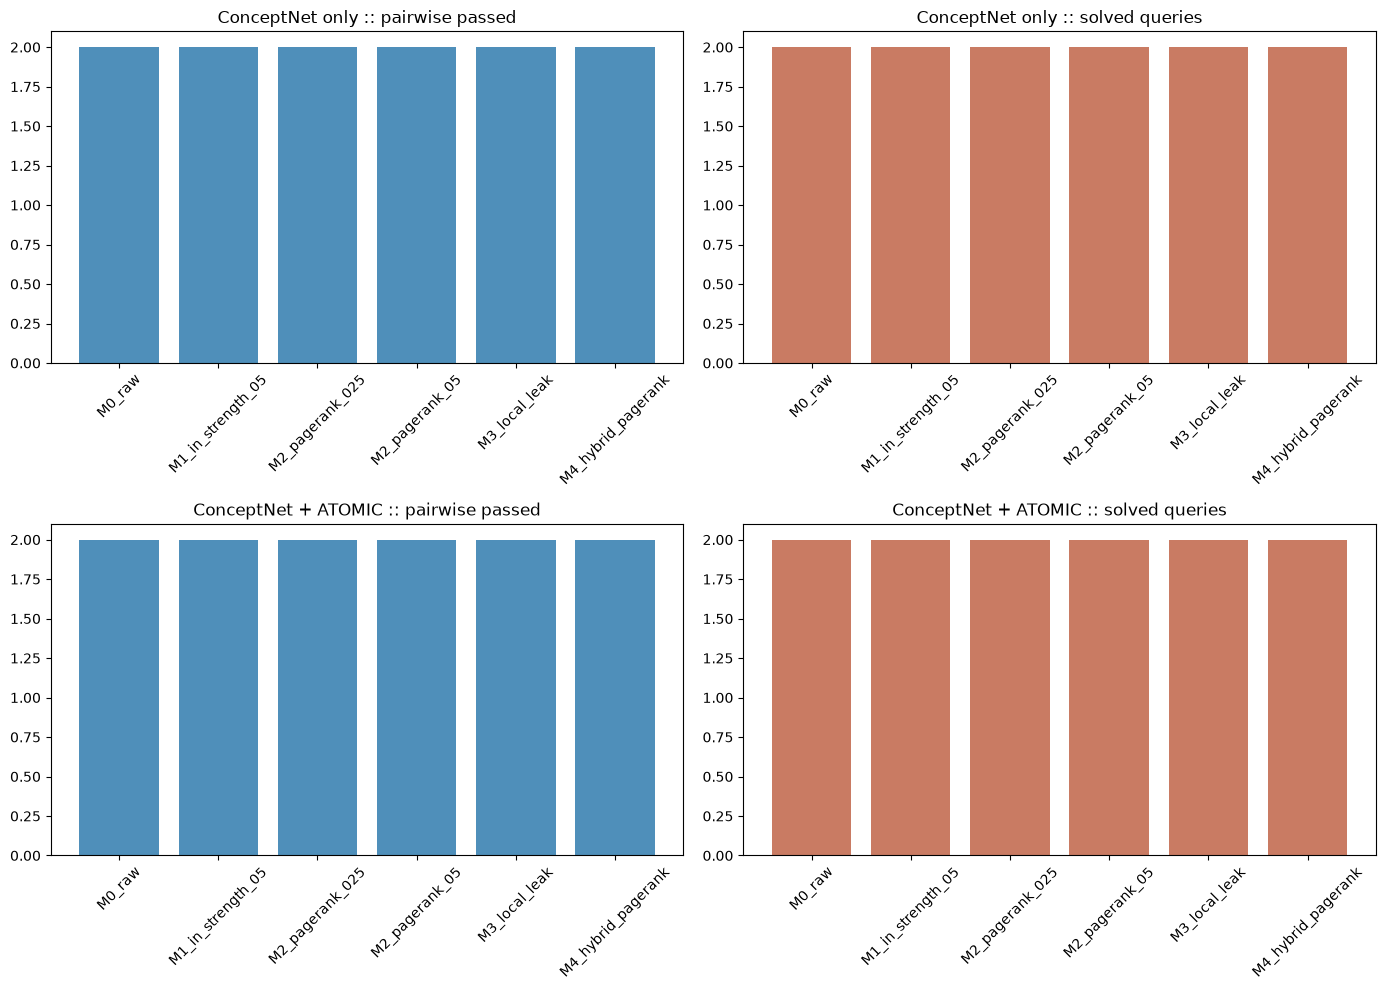

In [13]:
if plt is not None:
    graph_labels = [bundle['variant']['label'] for bundle in runs.values()]
    fig, axes = plt.subplots(len(runs), 2, figsize=(14, 5 * max(1, len(runs))))
    if len(runs) == 1:
        axes = [axes]
    for row_idx, (variant_name, bundle) in enumerate(runs.items()):
        method_names = list(bundle['methods'].keys())
        pairwise_passed = [bundle['methods'][name]['summary']['pairwise_passed'] for name in method_names]
        solved_queries = [bundle['methods'][name]['summary']['solved_queries'] for name in method_names]
        axes[row_idx][0].bar(method_names, pairwise_passed, color="#4f8fba")
        axes[row_idx][0].set_title(f"{bundle['variant']['label']} :: pairwise passed")
        axes[row_idx][0].tick_params(axis='x', rotation=45)
        axes[row_idx][1].bar(method_names, solved_queries, color="#c97b63")
        axes[row_idx][1].set_title(f"{bundle['variant']['label']} :: solved queries")
        axes[row_idx][1].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("matplotlib unavailable; skipping bar charts.")


## Interpretation checklist

When reading the output, answer these questions explicitly:

1. After excluding source nodes, do specific answers finally rise above generic hubs?
2. Does PageRank help more on the concept-only graph or on the concept+ATOMIC graph?
3. Does the local leak term add something non-redundant beyond the global prior?
4. If the hybrid wins here after 7a failed, does that mean 7a was mainly an anchoring problem?
5. If Variant B degrades strongly relative to Variant A, is ATOMIC currently helping retrieval or mostly distorting the topology?
